In [1]:
import cv2 as cv
import matplotlib.pyplot as plt

In [2]:
net = cv.dnn.readNetFromTensorflow("graph_opt.pb")

In [3]:
inWidth = 368
inHeight= 368
thr = 0.1

In [4]:
BODY_PARTS = { "Nose": 0, "Neck": 1, "RShoulder": 2, "RElbow": 3, "RWrist": 4,
               "LShoulder": 5, "LElbow": 6, "LWrist": 7, "RHip": 8, "RKnee": 9,
               "RAnkle": 10, "LHip": 11, "LKnee": 12, "LAnkle": 13, "REye": 14,
               "LEye": 15, "REar": 16, "LEar": 17, "Background": 18 }

POSE_PAIRS = [ ["Neck", "RShoulder"], ["Neck", "LShoulder"], ["RShoulder", "RElbow"],
               ["RElbow", "RWrist"], ["LShoulder", "LElbow"], ["LElbow", "LWrist"],
               ["Neck", "RHip"], ["RHip", "RKnee"], ["RKnee", "RAnkle"], ["Neck", "LHip"],
               ["LHip", "LKnee"], ["LKnee", "LAnkle"], ["Neck", "Nose"], ["Nose", "REye"],
               ["REye", "REar"], ["Nose", "LEye"], ["LEye", "LEar"] ]


In [5]:
img = cv.imread("posenew.jpeg")

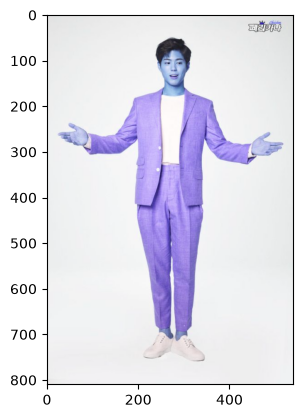

In [6]:
plt.imshow(img) #BGR

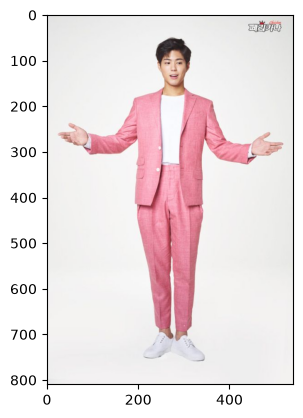

In [7]:
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)) # converted into RGB

In [8]:
def pose_estimation(frame):
    frameWidth = frame.shape[1]   
    frameHeight = frame.shape[0]
        
    blob= cv.dnn.blobFromImage(frame, 1.0, (inWidth, inHeight), (127.5, 127.5, 127.5), swapRB=True, crop=False)
    net.setInput(blob)
    out = net.forward()
    out = out[:, :19, :, :]  # MobileNet output [1, 57, -1, -1], we only need the first 19 elements

    assert(len(BODY_PARTS) == out.shape[1])

    points = []

    BODY_PARTS_REVERSE={v:k for k ,v in BODY_PARTS.items()}
    
    for i in range(len(BODY_PARTS)):
        # Slice heatmap of corresponging body's part.
        heatMap = out[0, i, :, :]

        # Originally, we try to find all the local maximums. To simplify a sample
        # we just find a global one. However only a single pose at the same time
        # could be detected this way.
        _, conf, _, point = cv.minMaxLoc(heatMap)
        x = int(round((frameWidth * point[0]) / out.shape[3]))
        y = int(round((frameHeight * point[1]) / out.shape[2]))
        # Add a point if it's confidence is higher than threshold.
        if(
            conf> thr
            and 0 <= x < frameWidth
            and 0 <= y <frameHeight
        ):
            points.append((x,y))
        else:
            points.append(None)

        #points.append((int(x), int(y)) if conf > thr else None)
        print(i, BODY_PARTS_REVERSE.get(i,"UNKNOWN"), "confidence=", round(conf,3), "raw point=", point, "iamge point=", points[-1])
 #draw only connetions with two valid endpoints.
    for partFrom, partTo in POSE_PAIRS:
        idFrom = BODY_PARTS[partFrom]
        idTo = BODY_PARTS[partTo]
    
        p1 = points[idFrom]
        p2 = points[idTo]
    
        if p1 is not None and p2 is not None:
            p1=tuple(map(int, p1))
            p2=tuple(map(int, p2))
            cv.line(
                    frame, p1, p2, (0, 255, 0), 3
                )
    
        # Draw all detected joints, even when a connected
        # skeleton line cannot be drawn.
            cv.circle(
                    frame, point, 4, (0, 0, 255), cv.FILLED
                )
            cv.circle(
                    frame, point, 4, (0, 0, 255), cv.FILLED
                )
    for point in points:
        if point is not None:
            cv.circle(
            frame,
            point,
            5,
            (0, 0, 255),
            cv.FILLED)
          
    
    t, _ = net.getPerfProfile()
    freq = cv.getTickFrequency() / 1000
    
    cv.putText(
            frame,
            f"{t / freq:.2f} ms",
            (10, 20),
            cv.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 0, 0),
            1
        )
    
    return frame


In [9]:
estimated_img= pose_estimation(img)

0 Nose confidence= 0.84 raw point= (23, 6) iamge point= (270, 106)
1 Neck confidence= 0.739 raw point= (23, 11) iamge point= (270, 194)
2 RShoulder confidence= 0.726 raw point= (17, 11) iamge point= (200, 194)
3 RElbow confidence= 0.686 raw point= (13, 15) iamge point= (153, 264)
4 RWrist confidence= 0.571 raw point= (8, 16) iamge point= (94, 282)
5 LShoulder confidence= 0.688 raw point= (29, 11) iamge point= (340, 194)
6 LElbow confidence= 0.776 raw point= (32, 16) iamge point= (376, 282)
7 LWrist confidence= 0.125 raw point= (37, 17) iamge point= (434, 299)
8 RHip confidence= 0.48 raw point= (19, 22) iamge point= (223, 387)
9 RKnee confidence= 0.472 raw point= (21, 31) iamge point= (247, 546)
10 RAnkle confidence= 0.567 raw point= (22, 39) iamge point= (258, 687)
11 LHip confidence= 0.51 raw point= (26, 22) iamge point= (305, 387)
12 LKnee confidence= 0.67 raw point= (25, 31) iamge point= (293, 546)
13 LAnkle confidence= 0.566 raw point= (24, 39) iamge point= (282, 687)
14 REye confi

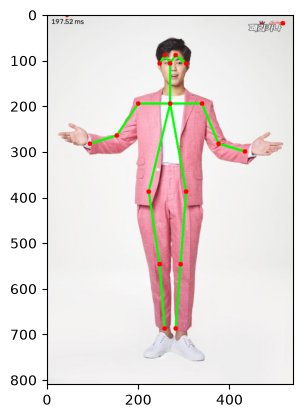

In [10]:
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))

In [11]:
# perform the same estimation on video


vid= cv.VideoCapture('video1.mp4')
vid.set(3,800)
vid.set(4,800)

if not vid.isOpened():
    vid= cv.VideoCapture(0)
if not vid.isOpened():
    raise IOError("Please Check. Cannot open Video")

while cv.waitKey(1) < 0:
    hasFrame,frame = vid.read()
    if not hasFrame:
        cv.waitKey()
        break
    frameWidth = frame.shape[1]   
    frameHeight = frame.shape[0]
        
    blob= cv.dnn.blobFromImage(frame, 1.0, (inWidth, inHeight), (127.5, 127.5, 127.5), swapRB=True, crop=False)
    net.setInput(blob)
    out = net.forward()
    out = out[:, :19, :, :]  # MobileNet output [1, 57, -1, -1], we only need the first 19 elements

    assert(len(BODY_PARTS) == out.shape[1])

    points = []

   # BODY_PARTS_REVERSE={v:k for k ,v in BODY_PARTS.items()}
    
    for i in range(len(BODY_PARTS)):
        # Slice heatmap of corresponging body's part.
        heatMap = out[0, i, :, :]

        # Originally, we try to find all the local maximums. To simplify a sample
        # we just find a global one. However only a single pose at the same time
        # could be detected this way.
        _, conf, _, point = cv.minMaxLoc(heatMap)
        x = int(round((frameWidth * point[0]) / out.shape[3]))
        y = int(round((frameHeight * point[1]) / out.shape[2]))
        # Add a point if it's confidence is higher than threshold.
        if(
            conf> thr
            and 0 <= x < frameWidth
            and 0 <= y <frameHeight
        ):
            points.append((x,y))
        else:
            points.append(None)

        #points.append((int(x), int(y)) if conf > thr else None)
       # print(i, BODY_PARTS_REVERSE.get(i,"UNKNOWN"), "confidence=", round(conf,3), "raw point=", point, "iamge point=", points[-1])
 #draw only connetions with two valid endpoints.
    for partFrom, partTo in POSE_PAIRS:
        idFrom = BODY_PARTS[partFrom]
        idTo = BODY_PARTS[partTo]
    
        p1 = points[idFrom]
        p2 = points[idTo]
    
        if p1 is not None and p2 is not None:
            p1=tuple(map(int, p1))
            p2=tuple(map(int, p2))
            cv.line(
                    frame, p1, p2, (0, 255, 0), 3
                )
    
        # Draw all detected joints, even when a connected
        # skeleton line cannot be drawn.
            cv.circle(
                    frame, point, 4, (0, 0, 255), cv.FILLED
                )
            cv.circle(
                    frame, point, 4, (0, 0, 255), cv.FILLED
                )
    for point in points:
        if point is not None:
            cv.circle(
            frame,
            point,
            5,
            (0, 0, 255),
            cv.FILLED)
          
    
    t, _ = net.getPerfProfile()
    freq = cv.getTickFrequency() / 1000
    
    cv.putText(
            frame,
            f"{t / freq:.2f} ms",
            (10, 20),
            cv.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 0, 0),
            1
        )
    cv.imshow('Pose Estimation Tutorial', frame)

KeyboardInterrupt: 

In [ ]:
# perform the same estimation on video


vid= cv.VideoCapture(1)

vid.set(cv.CAP_PROP_FPS, 20)
vid.set(3,800)
vid.set(4,800)

if not vid.isOpened():
    vid= cv.VideoCapture(0)
if not vid.isOpened():
    raise IOError("Please Check your Webcam. Cannot open Webcam")

while cv.waitKey(1) < 0:
    hasFrame,frame = vid.read()
    if not hasFrame:
        cv.waitKey()
        break
    frameWidth = frame.shape[1]   
    frameHeight = frame.shape[0]
        
    blob= cv.dnn.blobFromImage(frame, 1.0, (inWidth, inHeight), (127.5, 127.5, 127.5), swapRB=True, crop=False)
    net.setInput(blob)
    out = net.forward()
    out = out[:, :19, :, :]  # MobileNet output [1, 57, -1, -1], we only need the first 19 elements

    assert(len(BODY_PARTS) == out.shape[1])

    points = []

   # BODY_PARTS_REVERSE={v:k for k ,v in BODY_PARTS.items()}
    
    for i in range(len(BODY_PARTS)):
        # Slice heatmap of corresponging body's part.
        heatMap = out[0, i, :, :]

        # Originally, we try to find all the local maximums. To simplify a sample
        # we just find a global one. However only a single pose at the same time
        # could be detected this way.
        _, conf, _, point = cv.minMaxLoc(heatMap)
        x = int(round((frameWidth * point[0]) / out.shape[3]))
        y = int(round((frameHeight * point[1]) / out.shape[2]))
        # Add a point if it's confidence is higher than threshold.
        if(
            conf> thr
            and 0 <= x < frameWidth
            and 0 <= y <frameHeight
        ):
            points.append((x,y))
        else:
            points.append(None)

        #points.append((int(x), int(y)) if conf > thr else None)
       # print(i, BODY_PARTS_REVERSE.get(i,"UNKNOWN"), "confidence=", round(conf,3), "raw point=", point, "iamge point=", points[-1])
 #draw only connetions with two valid endpoints.
    for partFrom, partTo in POSE_PAIRS:
        idFrom = BODY_PARTS[partFrom]
        idTo = BODY_PARTS[partTo]
    
        p1 = points[idFrom]
        p2 = points[idTo]
    
        if p1 is not None and p2 is not None:
            p1=tuple(map(int, p1))
            p2=tuple(map(int, p2))
            cv.line(
                    frame, p1, p2, (0, 255, 0), 3
                )
    
        # Draw all detected joints, even when a connected
        # skeleton line cannot be drawn.
            cv.circle(
                    frame, point, 4, (0, 0, 255), cv.FILLED
                )
            cv.circle(
                    frame, point, 4, (0, 0, 255), cv.FILLED
                )
    for point in points:
        if point is not None:
            cv.circle(
            frame,
            point,
            5,
            (0, 0, 255),
            cv.FILLED)
          
    
    t, _ = net.getPerfProfile()
    freq = cv.getTickFrequency() / 1000
    
    cv.putText(
            frame,
            f"{t / freq:.2f} ms",
            (10, 20),
            cv.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 0, 0),
            1
        )
    cv.imshow('Pose Estimation Tutorial', frame)